Solution of the robust performance problem via $\mu$-synthesis.

Example from Skogestad & Postlethwaite 8.12.4
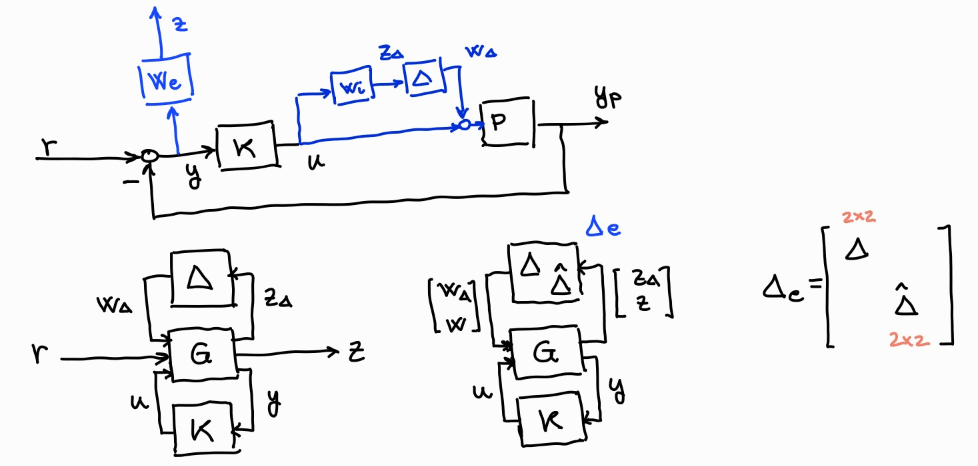

Plant uncertainty model is $P_p=P(I+\Delta W_i)$, with $W_i=w_i I$.

In [1]:
import matplotlib.pyplot as plt
from itertools import product
import slycot as sly
import numpy as np
import control as ct
import rpc_diism.robust as rb
import logging
import dkpy

In [2]:
# Plant P
den = [75, 1]
P = ct.tf(np.array([[[87.8], [-86.4]],
                   [[108.2], [-109.6]]]),
             np.array([[den, den],
                       [den, den]]))
display("Plant transfer function", P)

'Plant transfer function'

TransferFunction(
[[array([87.8]), array([-86.4])],
 [array([108.2]), array([-109.6])]],
[[array([75,  1]), array([75,  1])],
 [array([75,  1]), array([75,  1])]],
outputs=2, inputs=2)

Define performance weight and uncertainty weight 

'Uncertainty weight'

TransferFunction(
[[array([1. , 0.2]), array([0.])],
 [array([0.]), array([1. , 0.2])]],
[[array([0.5, 1. ]), array([1.])],
 [array([1.]), array([0.5, 1. ])]],
outputs=2, inputs=2)

'Performance weight'

TransferFunction(
[[array([0.5 , 0.05]), array([0.])],
 [array([0.]), array([0.5 , 0.05])]],
[[array([1.e+00, 1.e-06]), array([1.])],
 [array([1.]), array([1.e+00, 1.e-06])]],
outputs=2, inputs=2)

Text(0.5, 1.0, 'Frequency response of uncertainty and performance weights Wi, We')

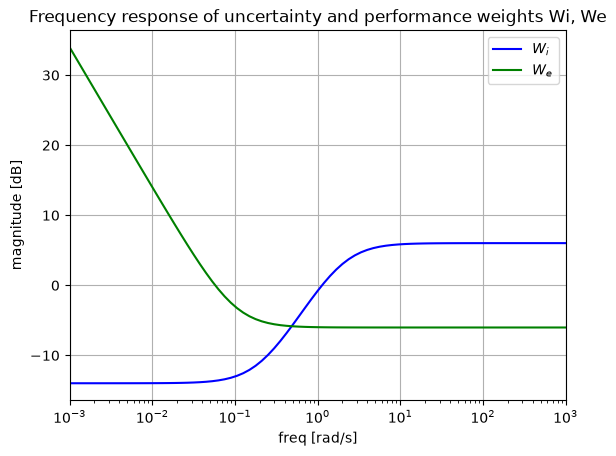

In [3]:
# Uncertainty block weight Wi
w_i = ct.tf([1,0.2],[0.5,1])
Wi = w_i.append(w_i) 
display("Uncertainty weight", Wi)

# Performance weight We (weight on S)
w_e = ct.tf([0.5,0.05],[1,1e-6])
We = w_e.append(w_e)
display("Performance weight", We)

# Frequency range for mu computations
omega = np.logspace(-3, 3, 81)

Wisv = rb.sigma(w_i, omega)
Wesv = rb.sigma(w_e, omega)

plt.semilogx(omega, 20*np.log10(Wisv[:, 0]), 'b', label=r'$W_i$')
plt.semilogx(omega, 20*np.log10(Wesv[:, 0]), 'g', label=r'$W_e$')
#plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Frequency response of uncertainty and performance weights Wi, We')

Uncertainty model with $\|\Delta\|_\infty<1$ approximately accounts for a 20% gain error and a neglected time delay of 0.9 (time is in minutes)


Construct the LFT

In [4]:
Wi.input_labels = ['u[0]', 'u[1]']
Wi.output_labels = ['zdelta[0]', 'zdelta[1]']
We.input_labels = ['y[0]', 'y[1]']
We.output_labels = ['z[0]', 'z[1]']
P.input_labels = ['up[0]','up[1]']
P.output_labels = ['yp[0]','yp[1]']

# Summing junction (multiplicative uncertainty)
sumdelta = ct.summing_junction(inputs=['u','wdelta'], output='up', dimension=2)

# Feedback: y = r-yp
fbk = ct.summing_junction(inputs=['w','-yp'], output='y', dimension=2)

# Generate the G transfer function of the LFT
G = ct.minreal(ct.interconnect([P, Wi, We, sumdelta, fbk],
                    inputs=['wdelta[0]','wdelta[1]','w[0]','w[1]','u[0]','u[1]'],
                    outputs=['zdelta[0]','zdelta[1]','z[0]','z[1]','y[0]','y[1]']), 
                    verbose=False)

Do $\mu$-synthesis.

INFO:DkIterFixedOrder:Iteration: 0, mu: 1.1792755126953125
INFO:DkIterFixedOrder:Iteration: 1, mu: 1.0292816162109375
INFO:DkIterFixedOrder:Iteration: 2, mu: 1.0207366943359375
INFO:DkIterFixedOrder:Iteration: 3, mu: 1.0123825073242188
INFO:DkIterFixedOrder:Iteration: 4, mu: 1.0065460205078125
INFO:DkIterFixedOrder:Iteration: 5, mu: 1.0019683837890625
INFO:DkIterFixedOrder:Iteration: 6, mu: 0.9972763061523438
INFO:DkIterFixedOrder:Iteration complete


'Peak upper bound (nubar): '

np.float64(0.9972763061523438)

Text(0.5, 1.0, '$\\bar\\mu$')

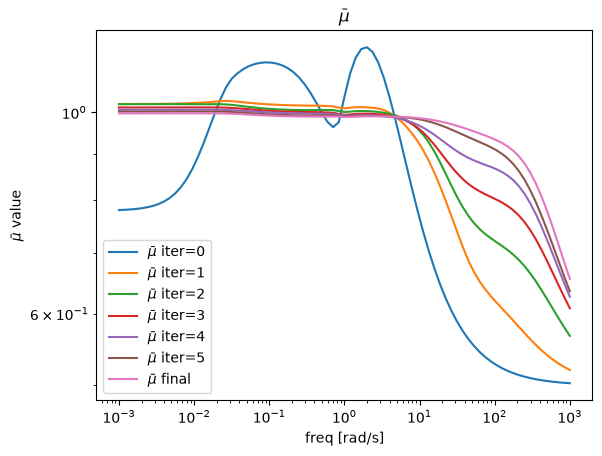

In [5]:
# Controller I/O sizes
f = 2

# Extended uncertainty structure: a 2x2 uncertainty block and a 2x2 performance block
structure = np.array([ [2,2] , [2,2] ])

# Do mu-synthesis using dkpy

# Enable logging of iterations
logging.basicConfig(level=logging.INFO)

# Number of iterations
numiter = 6

# Do D-K iteration: we use a 8th order interpolation for the D scalings and the 'lmi' method to solve the H-infinity problems
# Feel free to experiment with different orders and the method 'slicot'
K, best_nubar, iter_results = rb.musyn_dkpy(G, f, f, structure, omega, order=8, numiter=numiter, hinfmethod='lmi')

# Close the loop and evaluate the mu upper bound for the obtained controller
K.input_labels = ['y[0]','y[1]']
K.output_labels = ['u[0]','u[1]']
M = ct.interconnect([P, K, Wi, We, sumdelta, fbk],
                    inputs=['wdelta[0]','wdelta[1]','w[0]','w[1]'],
                    outputs=['zdelta[0]','zdelta[1]','z[0]','z[1]'])

# Compute mu upper bound and its maximum over frequency
mubar, nubar = rb.mucomp_dkpy(M, structure, omega)

display("Peak upper bound (nubar): ", nubar)

# Display the mu upper bound achieved throughout the iterations and the final one
for i in range(numiter):
    plt.loglog(omega, iter_results[i].mu_omega, label=r'$\bar \mu$ iter=%d' % i)
plt.loglog(omega, mubar, label=r'$\bar \mu$ final')

plt.ylabel(r'$\bar\mu$ value')
plt.xlabel('freq [rad/s]')
plt.legend()
plt.title(r'$\bar\mu$')

Verify performance on the nominal system. It must hold that $\|W_e S\|_\infty \leq 1$ since $\bar\nu< 1$. More precisely, we have $\|W_e S\|_\infty \leq \bar\nu$.

Text(0.5, 1.0, 'Singular values of S vs. inv(We) for the nominal system')

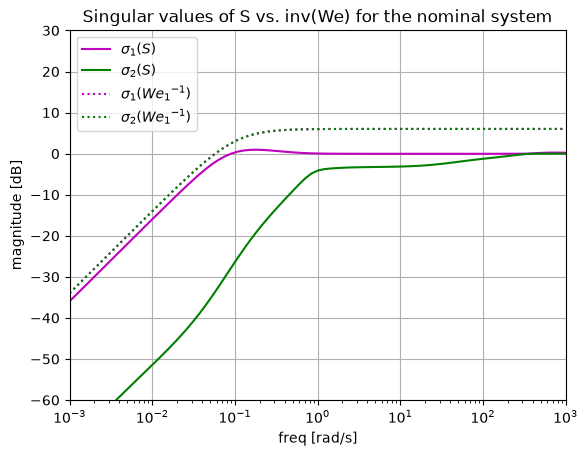

In [6]:
# Compute sensitivity for the nominal system
I = ct.ss([], [], [], np.eye(2)) # Identity system  
Delta = 0 * I
Delta.input_labels = ['zdelta[0]','zdelta[1]']
Delta.output_labels = ['wdelta[0]','wdelta[1]']               
K.input_labels = ['y[0]','y[1]']
K.output_labels = ['u[0]','u[1]'] 

S = ct.minreal(ct.interconnect([P, Delta, K, Wi, We, sumdelta, fbk],
                    inputs=['w[0]','w[1]'],
                    outputs=['y[0]','y[1]'], check_unused=False), verbose=False)

# Compute singular values of S over frequency
Ssv = rb.sigma(S, omega)

# Plot the singular values of invss(We) along with S
Weinv = rb.invss(ct.ss(We))
Weinvsv = rb.sigma(Weinv, omega)

plt.semilogx(omega, 20*np.log10(Ssv[:, 0]), 'm', label=r'$\sigma_1(S)$')
plt.semilogx(omega, 20*np.log10(Ssv[:, 1]), 'g', label=r'$\sigma_2(S)$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 0]), 'm:', label=r'$\sigma_1({We_1}^{-1})$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 1]), 'g:', label=r'$\sigma_2({We_1}^{-1})$')
plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Singular values of S vs. inv(We) for the nominal system')

Since $W_i$ is 0.2 at low frequency, and the uncertainty model is $P_p=P(I+W_i\Delta)$ with $\|\Delta\|_\infty < 1$, an input gain perturbation of $(I-0.2I)$ is such that $\|\Delta\|_\infty=1<1/\bar\nu$, considering that we have achieved a value of $\bar\nu$ slightly lower than 1. Therefore, this perturbation should guarantee that performance is preserved. Let us evaluate the performance under this perturbation.

Text(0.5, 1.0, 'Singular values of S vs. inv(We) for perturbed system')

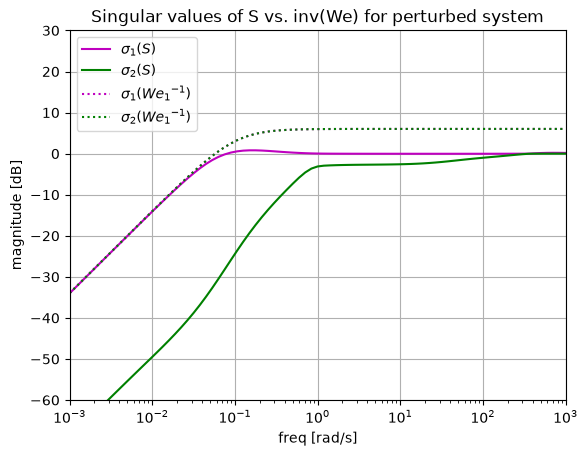

In [7]:
# Generate the perturbed plant
Pp = P*(I-0.2*I)
Pp.input_labels = ['up[0]','up[1]']
Pp.output_labels = ['yp[0]','yp[1]']

# Sensitivity of perturbed system
Sp = ct.interconnect([Pp, Delta, K, Wi, We, sumdelta, fbk],
                    inputs=['w[0]','w[1]'],
                    outputs=['y[0]','y[1]'], check_unused=False)

# Compute singular values of S over frequency
Spsv = rb.sigma(Sp, omega)

plt.semilogx(omega, 20*np.log10(Spsv[:, 0]), 'm', label=r'$\sigma_1(S)$')
plt.semilogx(omega, 20*np.log10(Spsv[:, 1]), 'g', label=r'$\sigma_2(S)$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 0]), 'm:', label=r'$\sigma_1({We_1}^{-1})$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 1]), 'g:', label=r'$\sigma_2({We_1}^{-1})$')
plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Singular values of S vs. inv(We) for perturbed system')

We see that the actual performance is very close to the bound $\|W_e S\|_\infty \leq 1$ at low frequencies. Let us compare $S$ with $\bar\nu W_e^{-1}$ for the perturbation $P_p=P(I-0.2/\bar\nu I)$, which lies in the set $\|\Delta\|_\infty=1/\bar\nu$, that is, on the boundary of the admissible perturbation set.

Text(0.5, 1.0, 'Singular values of S vs. nubar*inv(We) for perturbed system')

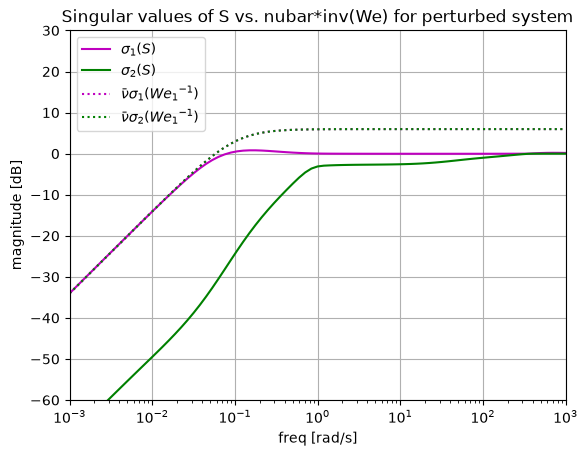

In [8]:
# Generate the perturbed plant
Pp = P*(I-0.2/nubar*I)
Pp.input_labels = ['up[0]','up[1]']
Pp.output_labels = ['yp[0]','yp[1]']

# Sensitivity of perturbed system
Sp = ct.interconnect([Pp, Delta, K, Wi, We, sumdelta, fbk],
                    inputs=['w[0]','w[1]'],
                    outputs=['y[0]','y[1]'], check_unused=False)

# Compute singular values of S over frequency
Spsv = rb.sigma(Sp, omega)

# Compare S with nubar*inv(We)
Weinvsv = nubar*rb.sigma(Weinv, omega)

plt.semilogx(omega, 20*np.log10(Spsv[:, 0]), 'm', label=r'$\sigma_1(S)$')
plt.semilogx(omega, 20*np.log10(Spsv[:, 1]), 'g', label=r'$\sigma_2(S)$')
plt.semilogx(omega, 20*np.log10(best_nubar*Weinvsv[:, 0]), 'm:', label=r'$\bar\nu \sigma_1({We_1}^{-1})$')
plt.semilogx(omega, 20*np.log10(best_nubar*Weinvsv[:, 1]), 'g:', label=r'$\bar\nu  \sigma_2({We_1}^{-1})$')
plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Singular values of S vs. nubar*inv(We) for perturbed system')

We see that for this perturbation (which satisfies $\|\Delta\|_\infty=1/\bar\nu$), $\sigma_1(S)$ is tight to $\bar\nu W_e^{-1}$, and therefore we have that $\|W_e S\|_\infty=\bar\nu$. On the other hand, from the robust performance theory, we know that the condition $\|M\|_{\mu_{\Delta_e}}=\gamma$ is equivalent to the existence of a perturbation with $\|\Delta\|_\infty=1/\gamma$ for which the performance $\|W_e S\|_\infty= \gamma$, corresponding to the singularity of $I-M\tilde\Delta$. This means two things: 1) The upper bound $\bar\nu$ is exactly the actual $\|M\|_\mu$, i.e., there is no gap between the two; 2) The perturbation that we have chosen is the "worst" possible perturbation on the boundary of the admissible set $\|\Delta\|_\infty=1/\bar\nu$, that is, the perturbation for which $\|W_e S\|_\infty$ is exactly $\|M\|_\mu$. There may indeed be other perturbations in the same set that do not hit the performance boundary, i.e., for which $\|W_e S\|_\infty<\bar\nu$. One such perturbation is $P_p=P(I+0.2/\bar\nu I)$, as shown below.

Text(0.5, 1.0, 'Singular values of S vs. nubar*inv(We) for perturbed system')

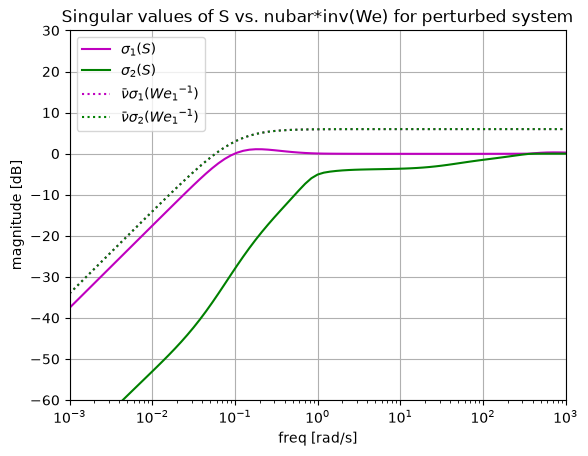

In [9]:
# Generate the perturbed plant
Pp = P*(I+0.2/nubar*I)
Pp.input_labels = ['up[0]','up[1]']
Pp.output_labels = ['yp[0]','yp[1]']

# Sensitivity of perturbed system
Sp = ct.interconnect([Pp, Delta, K, Wi, We, sumdelta, fbk],
                    inputs=['w[0]','w[1]'],
                    outputs=['y[0]','y[1]'], check_unused=False)

# Compute singular values of S over frequency
Spsv = rb.sigma(Sp, omega)

# Compare S with nubar*inv(We)
Weinvsv = nubar*rb.sigma(Weinv, omega)

plt.semilogx(omega, 20*np.log10(Spsv[:, 0]), 'm', label=r'$\sigma_1(S)$')
plt.semilogx(omega, 20*np.log10(Spsv[:, 1]), 'g', label=r'$\sigma_2(S)$')
plt.semilogx(omega, 20*np.log10(best_nubar*Weinvsv[:, 0]), 'm:', label=r'$\bar\nu \sigma_1({We_1}^{-1})$')
plt.semilogx(omega, 20*np.log10(best_nubar*Weinvsv[:, 1]), 'g:', label=r'$\bar\nu  \sigma_2({We_1}^{-1})$')
plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Singular values of S vs. nubar*inv(We) for perturbed system')

This clearly shows that for this perturbation $\|W_e S\|_\infty<\bar\nu$. 
An admissible perturbation is also $P_p=P(I+D_p/(1.01\bar\nu))$, where $D_p=\frac{0.2-s}{1+0.5s} I$, note that $W_i$ and $D_p$ have the same frequency response singular values.

Text(0.5, 1.0, 'Singular values of S vs. nubar*inv(We) for perturbed system')

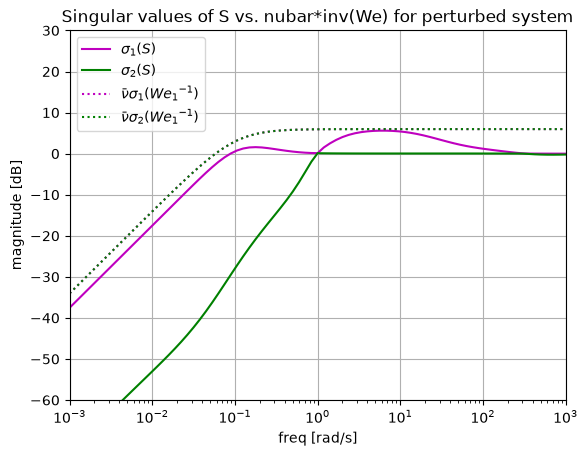

In [10]:
# Generate another admissible perturbed plant
Dp = 1/(1.01*nubar) * ct.tf([-1,0.2],[0.5,1])
Dp = Dp.append(Dp)

Pp2 = P*(I+Dp)
Pp2.input_labels = ['up[0]','up[1]']
Pp2.output_labels = ['yp[0]','yp[1]']

# Sensitivity of perturbed system
Sp2 = ct.interconnect([Pp2, Delta, K, Wi, We, sumdelta, fbk],
                    inputs=['w[0]','w[1]'],
                    outputs=['y[0]','y[1]'], check_unused=False)

# Compute singular values of S over frequency
Spsv = rb.sigma(Sp2, omega)

# Compare S with nubar*inv(We)
Weinvsv = nubar*rb.sigma(Weinv, omega)

plt.semilogx(omega, 20*np.log10(Spsv[:, 0]), 'm', label=r'$\sigma_1(S)$')
plt.semilogx(omega, 20*np.log10(Spsv[:, 1]), 'g', label=r'$\sigma_2(S)$')
plt.semilogx(omega, 20*np.log10(best_nubar*Weinvsv[:, 0]), 'm:', label=r'$\bar\nu \sigma_1({We_1}^{-1})$')
plt.semilogx(omega, 20*np.log10(best_nubar*Weinvsv[:, 1]), 'g:', label=r'$\bar\nu  \sigma_2({We_1}^{-1})$')
plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Singular values of S vs. nubar*inv(We) for perturbed system')

Observe that also in this case $\sigma_1(S)$ is almost tight to $\bar\nu W_e^{-1}$, but this time this does not occur at low frequencies.

Now, let's compare the step responses of the closed loop nominal and perturbed systems. Note that the steady state tracking error is almost independent of the perturbation. This is because the low-frequency sensitivity performance is ensured robustly and the actual sensitivity is very close to $\bar\nu|W_e^{-1}|$ at low frequencies in all cases!

Text(0.5, 1.0, 'Closed loop responses to reference [1,1]')

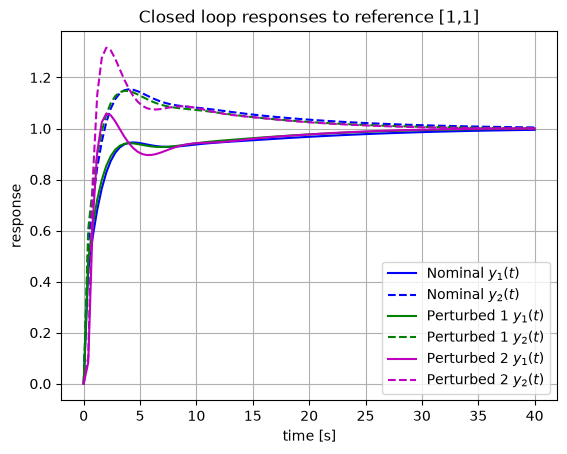

In [11]:
# Time for simulation
time = np.linspace(0, 40, 101)

# Compute complementary sensitivity for nominal, perturbed 1 and perturbed 2
T = I-S
Tp = I-Sp
Tp2 = I-Sp2

# Compute and plot unit step responses
_, y1 = ct.step_response(T, time, input=0, squeeze=True)
_, y2 = ct.step_response(T, time, input=1, squeeze=True)
y = y1+y2
_, yp1 = ct.step_response(Tp, time, input=0, squeeze=True)
_, yp2 = ct.step_response(Tp, time, input=1, squeeze=True)
yp= (yp1+yp2)
_, yp1_2 = ct.step_response(Tp2, time, input=0, squeeze=True)
_, yp2_2 = ct.step_response(Tp2, time, input=1, squeeze=True)
yp_2= (yp1_2+yp2_2)

plt.plot(time, y[0], 'b', label='Nominal $y_1(t)$')
plt.plot(time, y[1], 'b--', label='Nominal $y_2(t)$')
plt.plot(time, yp[0], 'g', label='Perturbed 1 $y_1(t)$')
plt.plot(time, yp[1], 'g--', label='Perturbed 1 $y_2(t)$')
plt.plot(time, yp_2[0], 'm', label='Perturbed 2 $y_1(t)$')
plt.plot(time, yp_2[1], 'm--', label='Perturbed 2 $y_2(t)$')
plt.xlabel('time [s]')
plt.ylabel('response')
plt.legend()
plt.grid()
plt.title('Closed loop responses to reference [1,1]')
